# 03b Perturbed: a perturbed copy of the CRAS model gives the verdicts known answers

**Slice.** The same room of the CRAS lab as 03a ("room B", the box in `01_cras_slice.json`, the 35 model elements that touch it, the 1 cm scan cache cut to the padded box). Here the model is the **perturbed model**: three walls moved by 1, 3 and 10 cm in an IFC copy, and three elements (one door, one column, one wall) treated as not built by leaving their scan points out of the comparison.

**Question.** When 03a's verdict logic, unchanged, is run on the perturbed model, does each injected change get the verdict it should (1 cm: OK, 3 and 10 cm: shifted, not built: not confirmed), and how many untouched elements get flagged shifted or missing that should not (the input to the 05 gate: at most 10 %)?

Sections: (1) load, (2) the real model as baseline (03a's frame and verdicts, which must reproduce 03a's counts), (3) the perturbed IFC and its manifest, with a check that only the moved walls changed, (4) the perturbed run, (5) scores, (6) outputs, then the answer. The baseline comes before the perturbation because the rules that pick the walls and the masks use the baseline's assignment of scan points to elements.

**03a's logic is copied, not imported** (the roadmap keeps stage logic inline until it is formalised): the parameters, the crop, the ICP refinement, the room-facing wall offsets with the wall side test of 03a (issue #17: which side of a wall a point was seen from; `occupancy`, `occupied_along`, `plane_vote`, `place_wall_points`, `measure`), `judge`. The parameters and rules are 03a's, wrapped in functions; exploration that the verdicts do not need (RANSAC check, residual tail, crop and sensitivity studies, winding table) is dropped. Nothing is tuned here: every parameter is 03a's.
Terms (scan, model, element, clutter, scan class, oracle labels, perturbed model, tolerance, verdict) are defined in [CONTEXT.md](../CONTEXT.md).
All randomness is seeded. Nothing is written outside `outputs/03b/` (gitignored); `data/` is only read.

In [1]:
import csv, json, os, resource, time
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import numpy as np

os.environ["OPEN3D_DISABLE_WEB_VISUALIZER"] = "true"  # before the import: skips Open3D's Jupyter web-visualizer banner
import open3d as o3d
import ifcopenshell
import ifcopenshell.util.placement as ifc_placement
import ifcopenshell.util.unit as ifc_unit
from IPython.display import Image, display

from scan_vs_bim.load import load_ifc_elements, merge_meshes

%config InlineBackend.figure_format = 'png'
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 100, "font.size": 9})
o3d.utility.set_verbosity_level(o3d.utility.VerbosityLevel.Error)
reg = o3d.pipelines.registration

# Parameters: 03a's, unchanged, with 03a's justification comments (03a's cross-references to its own sections kept as '03a's section N'). Lengths in metres.
SEED = 0
CRAS = Path("../data/cras")
CACHE, IFC = CRAS / "cras_voxel_1cm.npz", CRAS / "craslabbim.ifc"
SLICE = Path("01_cras_slice.json")  # written by notebook 01: recorded transform, room box, the 35 elements
OUT = Path("../outputs/03b")  # gitignored; never write outside outputs/
OUT.mkdir(parents=True, exist_ok=True)
PERTURBED_IFC = OUT / "craslabbim_perturbed.ifc"

CLASS_NAMES = ["unassigned", "ceiling", "floor", "wall", "door", "window", "desk", "chair", "cabinet", "mobile cabinet",
               "shelf", "vents", "water tank", "bin", "box", "board", "computer", "screen", "printer", "vest", "switch",
               "paper dispenser", "alcohol dispenser", "cable", "phone", "robot", "water kettle", "stairs", "ladder",
               "oil heater", "divider", "hanger", "fan", "water dispenser"]
ELEMENT_SCAN_CLASSES = ("ceiling", "floor", "wall", "door", "window", "stairs")
ELEMENT_CLASSES = ("IfcWallStandardCase", "IfcColumn", "IfcDoor", "IfcWindow", "IfcSlab", "IfcCovering", "IfcStairFlight")

TOL = 0.015  # USIBD LOA30: at most 15 mm at 2 sigma (95 %); quoted in 03a's section 3
BAND = 0.10  # (judgement call) scan points further than this from every element surface are ignored; the same as 00
PAD = BAND  # (judgement call) the room box is padded by this much when cropping, see 03a's section 3 for why
MIN_POINTS = 2000  # (judgement call) 1 cm voxels give one point per cm2, so 2000 points is about 0.2 m2 (a 45 cm square) of scanned surface
MIN_FRAC_OK = 0.95  # LOA30 is "specified at the 95 % confidence level": 15 mm is at 2 sigma, so 95 % of an element's points must lie within it
                    # (00's toy used 0.8; 03a's section 4 shows that value too)
MIN_FRAC_CLUSTER = 0.8  # (judgement call, not from the standard) shifted: share of points within TOL of the element's median. Clutter and element edges
                        # leave a real offset plane only 78 to 94 % near its median on this room, so 95 % is too strict here; 0.8 still rejects a 55/45 bimodal wall
SIDE_NEAR, SIDE_FAR, SIDE_STEP = 0.03, 0.20, 0.02  # (judgement call) wall side test: look this far from a wall point along the thickness axis: beyond the point's own surface noise,
                                                    # past a 10 cm drywall's other face, short of most furniture. Steps are one occupancy voxel
OCC_VOXEL = 0.02  # (judgement call) occupancy grid voxel for the side test: 2 cm, about 35 MB as a dense bool array over the crop
VOTE_BIN = 0.005  # plane vote: 5 mm bins along the thickness axis; the window is TOL each side (VOTE_HALF bins)
VOTE_HALF = round(TOL / VOTE_BIN)
VOTE_SHARE = 0.5  # (judgement call) a plane takes the side that more than half of all its points show by themselves; 03a's section 3 gives the reason
MIN_AREA_IN_BOX = 0.10  # (judgement call) below this share of an element's surface inside the room box, the in-box part is too small to stand for the element
PROBE = 0.05  # (judgement call) a wall face is room-facing if the point this far outside it, along its normal, is within the room box's extent

N_MODEL_SAMPLES, MODEL_CLIP = 3_000_000, 0.3  # points sampled on the 35 elements; kept within this margin of the box
ICP_DIST = 0.10  # plain point-to-plane ICP
ICP_FINE_DIST, TUKEY_K = 0.05, 0.02  # robust pass: Tukey loss gives residuals beyond 2 cm no weight
SANITY_ROT_DEG, SANITY_TRANS_M = 0.5, 0.05  # 03a's bounds on the ICP correction

# 03b: what is injected (decisions fixed before the run, see section 3)
MOVE_M = (0.01, 0.03, 0.10)  # three walls moved by these distances, into the room
EXPECTED_MOVED = {0.01: "OK", 0.03: "shifted", 0.10: "shifted"}  # absolute verdicts: 1 cm is inside the 15 mm tolerance, 3 and 10 cm are not
BASELINE_COUNTS = {"no_labels": {"OK": 5, "shifted": 0, "not confirmed": 30},  # 03a's answer: this notebook's copy of the logic must give them
                   "oracle_labels": {"OK": 6, "shifted": 1, "not confirmed": 28}}
BASE_TXT = " and ".join(" / ".join(str(v) for v in BASELINE_COUNTS[k].values()) for k in ("no_labels", "oracle_labels"))  # "5 / 0 / 30 and 6 / 1 / 28" 

T0 = time.time()
def peak_rss_gb():
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e9  # bytes on macOS


def apply(T, p):
    # Rigid transform T (4x4) applied to points p (n, 3); float32 in, float32 out.
    return (p @ T[:3, :3].T.astype(np.float32) + T[:3, 3].astype(np.float32)).astype(np.float32)

## 1. Load: the 35 room elements of the real model, then the scan cut to the room

As 03a section 1: the contract from notebook 01 (`frame.scan_to_model_4x4`, `room.box_model_frame`, the 35 GlobalIds), the 35 elements tessellated with `only_guids`, the scan cache transformed in chunks and cropped to the box padded by `PAD`. The crop is kept in the **recorded** frame (`P_REC`); each run applies its own ICP correction to it.

In [2]:
slice_ = json.loads(SLICE.read_text())
ROOM, FRAME = slice_["room"], slice_["frame"]
T_REC = np.array(FRAME["scan_to_model_4x4"])  # scan frame -> model frame, as recorded by 01
BOX = ROOM["box_model_frame"]
box_lo = np.array([BOX[k] for k in ("xmin", "ymin", "zmin")])
box_hi = np.array([BOX[k] for k in ("xmax", "ymax", "zmax")])
crop_lo, crop_hi = box_lo - PAD, box_hi + PAD
GUIDS = ROOM["element_global_ids"]
META = {e["global_id"]: e for e in ROOM["elements"]}
assert slice_["scanner_positions"]["recovered"] is False  # so missing / not visible are not reachable (03a: no scanner positions on CRAS)

t = time.time()
by_id = {e.global_id: e for e in load_ifc_elements(IFC, only_guids=GUIDS)}  # tessellation first: it has the higher memory peak
assert set(by_id) == set(GUIDS) and len(GUIDS) == 35, "not all 35 room elements were found in the IFC"
elements = [by_id[g] for g in GUIDS]
assert all(e.ifc_class in ELEMENT_CLASSES and e.ifc_class == META[e.global_id]["ifc_class"] for e in elements)
print(f"{len(elements)} elements tessellated in {time.time() - t:.0f} s, {sum(len(e.faces) for e in elements):,} triangles")

t = time.time()
cache = np.load(CACHE)
xyz, cls_all = cache["xyz"], cache["cls"]  # scan frame; the cache's rgb is not read
n_total = len(xyz)
parts, class_parts = [], []
for i in range(0, n_total, 4_000_000):
    p = apply(T_REC, xyz[i:i + 4_000_000])
    keep = ((p >= crop_lo) & (p <= crop_hi)).all(1)
    parts.append(p[keep])
    class_parts.append(cls_all[i:i + 4_000_000][keep])
del xyz, cls_all, cache
P_REC = np.concatenate(parts)  # room crop, model frame (recorded transform), float32
SCAN_CLASS = np.concatenate(class_parts)
del parts, class_parts
in_box = ((P_REC >= box_lo) & (P_REC <= box_hi)).all(1)
assert in_box.sum() == ROOM["scan_points_in_box"], "box crop differs from 01's count"
element_ids = [CLASS_NAMES.index(n) for n in ELEMENT_SCAN_CLASSES]
is_element_class = np.isin(SCAN_CLASS, element_ids)
is_clutter_class = ~is_element_class & (SCAN_CLASS != CLASS_NAMES.index("unassigned"))  # 03b: a scan class that is neither an element's nor 'unassigned'
print(f"cache {n_total:,} points -> {len(P_REC):,} in the box padded by {PAD * 100:.0f} cm ({time.time() - t:.0f} s); "
      f"element scan classes {is_element_class.sum():,}, clutter classes {is_clutter_class.sum():,}, unassigned {(SCAN_CLASS == 0).sum():,}")
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")

35 elements tessellated in 54 s, 195,576 triangles


cache 20,404,814 points -> 4,065,952 in the box padded by 10 cm (3 s); element scan classes 2,553,125, clutter classes 946,300, unassigned 566,527
peak RSS so far: 1.43 GB


## 2. The real model as baseline: 03a's frame and verdicts

Everything in this section is 03a's logic, wrapped in functions (`icp_target`, `refine`, `assign`, `verdict_rows`) with the same parameters and rules, which the baseline-count assert below checks: ICP refinement from the recorded transform (plain point-to-plane, then a Tukey robust pass, **all** room points, no labels, against points sampled on the model's 35 elements); every crop point assigned to the nearest element; the signed offset (for walls measured against the room-facing faces on the side each point was seen from, with the neighbouring room's surface left out, see 03a); `judge` for the verdict. Because it is written as functions of the model, section 4 runs the very same code on the perturbed model.

The baseline must reproduce 03a's counts (without labels 5 OK / 0 shifted / 30 not confirmed; with labels 6 / 1 / 28); that is asserted below, so any difference between this copy and 03a is caught.

In [3]:
# ---- 03a's logic, copied and wrapped in functions (same parameters and rules; the baseline-count assert checks it) ------------------------------------------------------------------------------------------
def delta(T_a, T_b, centroid):
    # How far apart two scan -> model transforms are: rotation (deg) between them, and the displacement (m) of the room centroid.
    residual = T_a @ np.linalg.inv(T_b)
    angle = np.degrees(np.arccos(np.clip((np.trace(residual[:3, :3]) - 1) / 2, -1, 1)))
    return angle, np.linalg.norm(residual[:3, :3] @ centroid + residual[:3, 3] - centroid)


def icp_target(els):
    # Points sampled on the elements (all faces), kept within MODEL_CLIP of the box; and the centroid of those within the scan crop.
    o3d.utility.random.seed(SEED)
    sampled = merge_meshes(els).sample_points_uniformly(N_MODEL_SAMPLES, use_triangle_normal=True)
    q = np.asarray(sampled.points)
    target = sampled.select_by_index(np.flatnonzero(((q >= box_lo - MODEL_CLIP) & (q <= box_hi + MODEL_CLIP)).all(1)))
    q = np.asarray(target.points)
    return target, q[((q >= crop_lo) & (q <= crop_hi)).all(1)].mean(0)


def refine(points, target):
    # ICP from the recorded transform: the scan is already in the model frame under T_REC, so ICP starts at the identity and its result
    # is the correction in the model frame: T_refined = correction @ T_REC.
    src = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(points.astype(np.float64)))
    est = reg.TransformationEstimationPointToPlane
    plain = reg.registration_icp(src, target, ICP_DIST, np.eye(4), est(), reg.ICPConvergenceCriteria(1e-8, 1e-8, 50))
    robust = reg.registration_icp(src, target, ICP_FINE_DIST, plain.transformation, est(reg.TukeyLoss(TUKEY_K)),
                                  reg.ICPConvergenceCriteria(1e-8, 1e-8, 100))
    return plain, robust


def mesh_of(e, flip=False):
    f = e.faces[:, [0, 2, 1]] if flip else e.faces
    m = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(e.vertices), o3d.utility.Vector3iVector(f))
    m.compute_triangle_normals()
    return m


def judge(s, area_frac=1.0, min_points=MIN_POINTS, min_frac=MIN_FRAC_OK, min_cluster=MIN_FRAC_CLUSTER):
    # One element's verdict from its signed offsets s (metres, within BAND) and the share of its surface inside the box.
    n = len(s)
    median = float(np.median(s)) if n else float("nan")
    spread = 1.4826 * float(np.median(np.abs(s - median))) if n else float("nan")  # robust sigma, informational only
    share = float(np.mean(np.abs(s) <= TOL)) if n else 0.0
    one_cluster = float(np.mean(np.abs(s - median) <= TOL)) if n else 0.0  # share of points within TOL of the median
    if area_frac < MIN_AREA_IN_BOX:
        verdict, reason = "not confirmed", "mostly outside the room box"
    elif n < min_points:
        verdict, reason = "not confirmed", "too few points"
    elif share >= min_frac:
        verdict, reason = "OK", ""
    elif abs(median) > TOL and one_cluster >= min_cluster:
        verdict, reason = "shifted", ""
    else:
        verdict, reason = "not confirmed", "inconsistent offsets"
    return dict(verdict=verdict, reason=reason, point_count=n, median_m=median, spread_m=spread, share_within_tol=share,
                cluster_share=one_cluster)


def room_facing(e, lo, hi):
    # Boolean per triangle of a wall: vertical faces whose outward normal points into the box [lo, hi] (plan view); the box is taken along the
    # normal only, because a wall runs on beyond the box and its triangles there still face the same way.
    n = np.asarray(mesh_of(e).triangle_normals)
    probe = e.vertices[e.faces].mean(1) + PROBE * n
    a, b = n[:, :2] * lo[:2], n[:, :2] * hi[:2]
    s = (probe[:, :2] * n[:, :2]).sum(1)
    return (np.abs(n[:, 2]) < 0.5) & (s >= np.minimum(a, b).sum(1)) & (s <= np.maximum(a, b).sum(1))


def closest_signed(scene, normals, first, pts):
    # Nearest triangle of the scene to each point: its geometry id, the distance, and the offset along that triangle's normal.
    geom, dist, signed = np.empty(len(pts), np.int32), np.empty(len(pts), np.float32), np.empty(len(pts), np.float32)
    for i in range(0, len(pts), 500_000):
        p = np.ascontiguousarray(pts[i:i + 500_000], dtype=np.float32)
        r = scene.compute_closest_points(o3d.core.Tensor(p))
        g, prim, foot = r["geometry_ids"].numpy(), r["primitive_ids"].numpy(), r["points"].numpy()
        geom[i:i + 500_000] = g
        dist[i:i + 500_000] = np.linalg.norm(p - foot, axis=1)
        signed[i:i + 500_000] = np.einsum("ij,ij->i", p - foot, normals[first[g] + prim])
    return geom, dist, signed


def occupancy(pts):
    # Dense boolean grid over the points' bounding box: True where a voxel of OCC_VOXEL holds at least one scan point.
    lo = pts.min(0).astype(np.float64)
    grid = np.zeros(np.ceil((pts.max(0) - lo) / OCC_VOXEL).astype(int) + 1, bool)
    j = np.floor((pts - lo) / OCC_VOXEL).astype(int)
    grid[j[:, 0], j[:, 1], j[:, 2]] = True
    return lo, grid


def occupied_along(occ, p, axis, sign):
    # Per point: is any voxel occupied from SIDE_NEAR to SIDE_FAR away along sign * axis? Outside the grid counts as free.
    lo, grid = occ
    hit = np.zeros(len(p), bool)
    for d in np.arange(SIDE_NEAR, SIDE_FAR + 1e-9, SIDE_STEP):
        q = p.astype(np.float64)
        q[:, axis] += sign * d
        j = np.floor((q - lo) / OCC_VOXEL).astype(int)
        inside = ((j >= 0) & (j < grid.shape)).all(1)
        hit[inside] |= grid[j[inside, 0], j[inside, 1], j[inside, 2]]
    return hit


def plane_vote(u, facing, share):
    # Per point: the side its surface plane shows as a whole, or 0. u: the points' coordinate along the wall's thickness axis; facing: what each
    # point shows by itself (1, -1 or 0). A plane is the points within TOL of u (VOTE_HALF bins of VOTE_BIN each side); it takes a side if more than
    # `share` of all its points show that side by themselves.
    b = np.floor((u - u.min()) / VOTE_BIN).astype(int)
    window = np.ones(2 * VOTE_HALF + 1)
    count = lambda m: np.convolve(np.bincount(b[m], minlength=b.max() + 1), window, "same")[b]
    total, plus, minus = count(np.ones(len(u), bool)), count(facing == 1), count(facing == -1)
    return np.where(plus > share * total, 1, np.where(minus > share * total, -1, 0))


def place_wall_points(e, face_set, p, fallback, occ, vote_share=VOTE_SHARE):
    # The scan points p (assigned to wall e, within BAND) -> their signed offsets along the reference side's normal, NaN for the points that are the
    # back of the wall; `fallback` is the offset by the nearest room-facing face (the rule before the side test), used where the side is ambiguous.
    # Returns the offsets, how each point was decided (1: free space on one side only, 2: its plane's side, 3: ambiguous, fallback) and a dict of counts.
    n = np.asarray(mesh_of(e).triangle_normals)
    a = int(np.argmin(np.ptp(e.vertices[:, :2], axis=0)))  # the thickness axis in plan
    assert np.all(np.minimum(np.abs(n[face_set, 0]), np.abs(n[face_set, 1])) < 1e-3), "a wall is not aligned with the model axes"
    broad = {s: face_set & (n[:, a] * s > 0.99) for s in (1, -1)}  # the wall's two big faces (end faces left out), by the sign of their normal along the axis
    sides = [s for s in (1, -1) if broad[s].any()]  # room-facing sides: 1 for a boundary wall, 2 for a partition inside the box
    assert sides, "a wall has no room-facing side"
    free_plus, free_minus = ~occupied_along(occ, p, a, +1), ~occupied_along(occ, p, a, -1)
    own = np.where(free_plus & ~free_minus, 1, np.where(~free_plus & free_minus, -1, 0))  # the direction the surface was seen from; 0: ambiguous
    plane = plane_vote(p[:, a], own, vote_share) if vote_share is not None else np.zeros(len(p), int)  # vote_share None: no plane vote
    facing = np.where(plane != 0, plane, own)  # a plane that most of its own points see from one side takes that side, also from the ones that say otherwise
    off = {}  # per room-facing side: the offset to that side's faces, along its outward normal
    for s in sides:
        sub = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(e.vertices), o3d.utility.Vector3iVector(e.faces[broad[s]]))
        sub_scene = o3d.t.geometry.RaycastingScene()
        sub_scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(sub))
        _, d_face, s_face = closest_signed(sub_scene, n[broad[s]], np.zeros(1, int), p)
        off[s] = np.copysign(d_face, s_face)
    side = np.zeros(len(p), int)  # the room-facing side each point is measured against
    dropped = np.zeros(len(p), bool)  # seen from a side that is not room-facing: the neighbouring room's surface
    for s in (1, -1):
        if s in sides:
            side[facing == s] = s
        else:
            dropped |= facing == s
    ambiguous = facing == 0
    side[ambiguous] = np.where(np.abs(off[1][ambiguous]) <= np.abs(off[-1][ambiguous]), 1, -1) if len(sides) == 2 else sides[0]
    n_side = {s: int(((side == s) & ~dropped).sum()) for s in sides}
    ref = sides[0] if len(sides) == 1 else (1 if n_side[1] >= n_side[-1] else -1)  # reference side: the one with more points, ties to +axis
    sign = np.where(side == ref, 1.0, -1.0)  # the other side's offsets are flipped onto the reference normal
    signed = np.where(ambiguous, fallback, np.where(side == 1, off[1] if 1 in sides else 0, off[-1] if -1 in sides else 0)) * sign
    signed = signed.astype(np.float32)
    signed[dropped] = np.nan
    how = np.where(ambiguous, 3, np.where(facing == own, 1, 2)).astype(np.int8)
    info = dict(axis=a, sides=sides, ref=ref, n_band=len(p), n_dropped=int(dropped.sum()), n_ambiguous=int(ambiguous.sum()), n_side=n_side,
                n_by_plane=int((how == 2).sum()), n_overruled=int(((own != 0) & (facing != own)).sum()))
    return signed, how, info


def measure(els, faces, pts, vote_share=VOTE_SHARE):
    # Returns per point: the element index, the distance to it, the signed offset, the offset by 00's nearest-triangle rule, and what the wall side
    # test decided. faces[i]: boolean per triangle of element i, the triangles its offset is measured against (all True is 00's rule).
    # For a wall (not all True) the offset is along the reference side's normal, and NaN for a point that is the back of the wall.
    scene, normal_list, first = o3d.t.geometry.RaycastingScene(), [], [0]
    for e in els:
        normal_list.append(np.asarray(mesh_of(e).triangle_normals))
        scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(mesh_of(e)))  # geometry ids follow this order
        first.append(first[-1] + len(e.faces))
    geom, dist, nearest = closest_signed(scene, np.concatenate(normal_list), np.array(first), pts)
    signed = nearest.copy()
    how, walls_info, occ, fallback_all = np.zeros(len(pts), np.int8), {}, None, np.full(len(pts), np.nan, np.float32)
    for i, keep in enumerate(faces):
        if keep.all():
            continue
        idx = np.flatnonzero((geom == i) & (dist <= BAND))  # only the points that enter the comparison
        sub = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(els[i].vertices), o3d.utility.Vector3iVector(els[i].faces[keep]))
        sub_scene = o3d.t.geometry.RaycastingScene()
        sub_scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(sub))
        _, d_face, s_face = closest_signed(sub_scene, normal_list[i][keep], np.zeros(1, int), pts[idx])
        fallback = np.copysign(d_face, s_face)  # the sign along the normal, the size as the distance: a point past a face's edge (above the wall's top) is not at offset 0
        fallback_all[idx] = fallback
        occ = occ or occupancy(pts)  # all points of the crop, once
        signed[idx], how[idx], walls_info[i] = place_wall_points(els[i], keep, pts[idx], fallback, occ, vote_share)
    return geom, dist, signed, nearest, SimpleNamespace(how=how, walls=walls_info, fallback=fallback_all)


def area_fractions(els):
    # How much of each element's surface lies inside the box itself (surface samples, about 200 per m2)
    o3d.utility.random.seed(SEED)
    out = []
    for e in els:
        m = mesh_of(e)
        pts = np.asarray(m.sample_points_uniformly(int(np.clip(m.get_surface_area() * 200, 2000, 200_000))).points)
        out.append(float(((pts >= box_lo) & (pts <= box_hi)).all(1).mean()))
    return out


def assign(els, pts):
    # Assign every crop point to its nearest element; signed offsets, walls against their room-facing faces on the side each point was seen from.
    faces = [room_facing(e, box_lo, box_hi) if e.ifc_class == "IfcWallStandardCase" else np.ones(len(e.faces), bool) for e in els]
    assert all(f.any() for e, f in zip(els, faces) if e.ifc_class == "IfcWallStandardCase"), "a wall has no room-facing face"
    geom_id, distance, signed, _, side_test = measure(els, faces, pts)
    band = distance <= BAND
    in_band = band & ~np.isnan(signed)  # the counted points: within the band, and not the back of a wall
    points_of = [np.flatnonzero((geom_id == i) & in_band) for i in range(len(els))]  # per element: indices of its counted points
    band_of = [np.flatnonzero((geom_id == i) & band) for i in range(len(els))]  # 03b: all its points in the band, the back of a wall included
    return SimpleNamespace(signed=signed, points_of=points_of, band_of=band_of, walls=side_test.walls, how=side_test.how, area_in_box=area_fractions(els))


def verdict_rows(els, A, use):
    # use: boolean mask over the crop points that enter the comparison. One row per element.
    rows = []
    for i, e in enumerate(els):
        idx = A.points_of[i]
        j = judge(A.signed[idx[use[idx]]].astype(np.float64), A.area_in_box[i])
        rows.append(dict(global_id=e.global_id, ifc_class=e.ifc_class, name=META[e.global_id]["name"], verdict=j["verdict"], reason=j["reason"],
                         point_count=j["point_count"], median_mm=j["median_m"] * 1000, share_within_tol=j["share_within_tol"],
                         share_near_median=j["cluster_share"], area_in_box_frac=A.area_in_box[i]))
    return rows


def counts(rows):
    return {v: sum(r["verdict"] == v for r in rows) for v in ("OK", "shifted", "not confirmed")}
# ---- end of 03a's logic ------------------------------------------------------------------------------------------------------------

# Known answer on synthetic offsets (03a's check, shortened): the copy of `judge` behaves
rs = np.random.default_rng(SEED)
assert judge(rs.normal(0.03, 0.003, 5000))["verdict"] == "shifted" and judge(rs.normal(0.0, 0.003, 5000))["verdict"] == "OK"
assert judge(rs.normal(0.03, 0.003, 50))["verdict"] == "not confirmed" and judge(rs.uniform(-0.05, 0.05, 5000))["verdict"] == "not confirmed"
assert judge(np.concatenate([rs.normal(0.04, 0.003, 2750), rs.normal(0.0, 0.003, 2250)]))["verdict"] == "not confirmed"

In [4]:
# Baseline run on the real model: frame, assignment, verdicts with and without oracle labels
t = time.time()
target_real, c_room = icp_target(elements)
_, robust_real = refine(P_REC, target_real)
T_REAL = robust_real.transformation @ T_REC
rot, trans = delta(T_REAL, T_REC, c_room)
print(f"real model: ICP correction vs the recorded transform: rotation {rot:.3f} deg, room centroid {trans * 1000:.1f} mm ({time.time() - t:.0f} s)")
assert rot < SANITY_ROT_DEG and trans < SANITY_TRANS_M, "ICP moved the room by more than the sanity bounds"
P_REAL = apply(robust_real.transformation, P_REC)
A_REAL = assign(elements, P_REAL)
del P_REAL
use_all, use_oracle = np.ones(len(P_REC), bool), is_element_class
BASE = {"no_labels": verdict_rows(elements, A_REAL, use_all), "oracle_labels": verdict_rows(elements, A_REAL, use_oracle)}
print(f"{'':16s}{'without labels':>16s}{'with labels':>13s}   (03a: {BASE_TXT})")
for v in ("OK", "shifted", "not confirmed"):
    print(f"{v:16s}{counts(BASE['no_labels'])[v]:16d}{counts(BASE['oracle_labels'])[v]:13d}")
for variant in BASE:
    assert counts(BASE[variant]) == BASELINE_COUNTS[variant], f"baseline {variant} differs from 03a: {counts(BASE[variant])}"
print("baseline reproduces 03a's counts")
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")

real model: ICP correction vs the recorded transform: rotation 0.112 deg, room centroid 6.8 mm (69 s)


                  without labels  with labels   (03a: 5 / 0 / 30 and 6 / 1 / 28)
OK                             5            6
shifted                        0            1
not confirmed                 30           28
baseline reproduces 03a's counts
peak RSS so far: 1.43 GB


## 3. The perturbed IFC and its manifest

**Moves are IFC changes.** Three walls are moved perpendicular to their face (in plan, towards the room box centre) by 1, 3 and 10 cm, in a copy of the IFC written to `outputs/03b/`. Which walls (rule, fixed before looking at results):

- the candidates are the room's `IfcWallStandardCase` elements **entirely inside the room box** (`inside_box`), so that the whole wall is judged and the sliver rule cannot decide the verdict; a wall that crosses a box face is judged on a part only;
- among them the three with the **most oracle-label scan points** assigned (the baseline's assignment, element-class scan points within `BAND`, counted before 03a's side test leaves out the back of a wall, so that the same three walls are moved by the same amounts as before the side test and the numbers stay comparable): the best-measured walls give the most informative control;
- the wall with the most points gets the 1 cm move (the control that should stay OK), the next 3 cm, the next 10 cm.

**Deletions are in-memory scan masks, not IFC changes.** "Deleted" means not built: the element stays in the perturbed IFC and the scan points of the element scan classes (ceiling, floor, wall, door, window, stairs) that the baseline assigns to it within `BAND` are left out of the comparison; clutter-class points stay (the clutter that hides it is still there). The door and the column are the room's only ones. The wall "where clutter hides it" is the room wall (any of the 11, moved walls excluded) with the **highest share of clutter-class points among the points assigned to it without labels**. "Clutter-class" means a scan class that is neither one of the element classes nor `unassigned`; the dataset's `unassigned` points are not counted as clutter. (A first version of this rule restricted the choice to walls inside the box; no wall inside the box has any clutter-class points, so every share was 0 % and the choice was an arbitrary tie. The rule as given, over all room walls, has a clear winner.)

**How a move is applied.** Walls in this Revit export carry their geometry in their own local placement, and their openings, windows and doors hang off it (`PlacementRelTo`). Moving the wall's placement alone would drag them along. So the wall's `IfcLocalPlacement` is shifted, the placement of each window or door the wall hosts is shifted back by the same world vector (so it stays where it was), and the wall's `IfcOpeningElement`s move with the wall (they are part of the wall's cut; the window then sits in a hole that moved with the wall, by 1 to 10 cm perpendicular to it). New `IfcCartesianPoint` and `IfcAxis2Placement3D` entities are created instead of editing existing ones in place, so nothing shared can move by accident. The manifest records the consequence of each move: `carried` lists the opening elements that moved with the wall (by the wall's offset), `held_in_place` the windows/doors whose placements were compensated (net offset zero). The check after writing re-reads the manifest and re-opens the IFC.

In [5]:
# Candidates, ranked: oracle-label points and clutter share per wall (baseline assignment, no labels / labels)
walls = [i for i, e in enumerate(elements) if e.ifc_class == "IfcWallStandardCase"]
stat = {}
for i in walls:
    idx = A_REAL.band_of[i]
    stat[i] = dict(n_all=len(idx), n_oracle=int(is_element_class[idx].sum()), n_clutter=int(is_clutter_class[idx].sum()), n_unassigned=int((SCAN_CLASS[idx] == 0).sum()),
                   inside=META[GUIDS[i]]["inside_box"])
    stat[i]["clutter_share"] = stat[i]["n_clutter"] / max(stat[i]["n_all"], 1)
print(f"{'#':>2s} {'wall':26s} {'inside box':>10s} {'points (all)':>13s} {'oracle-label':>13s} {'clutter-class':>14s} {'unassigned':>11s} {'clutter share':>14s}")
for i in sorted(walls, key=lambda i: -stat[i]["n_oracle"]):
    s = stat[i]
    print(f"{i:2d} {META[GUIDS[i]]['name'][-24:]:26s} {'yes' if s['inside'] else 'no':>10s} {s['n_all']:13,d} {s['n_oracle']:13,d} {s['n_clutter']:14,d} {s['n_unassigned']:11,d} {s['clutter_share']:14.1%}")

candidates = [i for i in walls if stat[i]["inside"]]
moved_idx = sorted(candidates, key=lambda i: (-stat[i]["n_oracle"], i))[:3]
mask_wall = max((i for i in walls if i not in moved_idx), key=lambda i: stat[i]["clutter_share"])
shares_left = sorted(s["clutter_share"] for i, s in stat.items() if i not in moved_idx)
assert shares_left[-1] > shares_left[-2], "tie for the clutter wall"
door_idx = [i for i, e in enumerate(elements) if e.ifc_class == "IfcDoor"]
column_idx = [i for i, e in enumerate(elements) if e.ifc_class == "IfcColumn"]
assert len(door_idx) == 1 and len(column_idx) == 1 and len(moved_idx) == 3
assert GUIDS[door_idx[0]] == "0WU0DUvgT6tu4IXFc9kNX5" and GUIDS[column_idx[0]] == "054HMVvnL1EOSZl$bniLeG"
print(f"\nmoved (most oracle-label points, inside the box): " + ", ".join(f"{META[GUIDS[i]]['name'][-10:]} ({stat[i]['n_oracle']:,})" for i in moved_idx))
print(f"clutter wall (highest clutter share, not moved): {META[GUIDS[mask_wall]]['name'][-10:]} "
      f"({stat[mask_wall]['clutter_share']:.1%}: {stat[mask_wall]['n_clutter']:,} of its {stat[mask_wall]['n_all']:,} points are clutter-class, {stat[mask_wall]['n_oracle']:,} element-class)")

 # wall                       inside box  points (all)  oracle-label  clutter-class  unassigned  clutter share
 9 ll:(10cm) Drywall:961571          yes       328,138       265,408         23,448      39,282           7.1%
13 ll:(10cm) Drywall:973242          yes       360,985       257,873         32,384      70,728           9.0%
 8 to pintura branca:919433           no       188,976       176,404          5,406       7,166           2.9%
11 ll:(10cm) Drywall:962532           no       148,667       127,466              0      21,201           0.0%
18 ll:(10cm) Drywall:979093           no        59,804        50,550          5,625       3,629           9.4%
15 ll:(10cm) Drywall:976743           no        10,786        10,220              0         566           0.0%
16 ll:(10cm) Drywall:978670          yes         6,696         6,037              0         659           0.0%
12 ll:(10cm) Drywall:971319           no        10,596         5,802             19       4,775           0.2%
1

In [6]:
# The moves' direction: the wall's thickness axis in plan, pointing at the room box centre; model-frame vectors
centre = (box_lo + box_hi) / 2
def room_direction(e):
    v = e.vertices
    ext = np.ptp(v[:, :2], axis=0)
    a = int(np.argmin(ext))
    assert ext[a] < 0.2, "not a thin wall"
    n = np.asarray(mesh_of(e).triangle_normals)
    vertical = np.abs(n[:, 2]) < 0.5
    assert np.all(np.minimum(np.abs(n[vertical, 0]), np.abs(n[vertical, 1])) < 1e-3), "wall is not aligned with the model axes"
    u = np.zeros(3)
    u[a] = 1.0 if centre[a] > (v[:, a].min() + v[:, a].max()) / 2 else -1.0
    return u

OFFSETS = {GUIDS[i]: room_direction(elements[i]) * d for i, d in zip(moved_idx, MOVE_M)}
for i, d in zip(moved_idx, MOVE_M):
    print(f"{META[GUIDS[i]]['name'][-10:]}: {d * 100:.0f} cm along {OFFSETS[GUIDS[i]].round(3)} (model frame, towards the room box centre {centre.round(2)})")

# Masks: the baseline's element-class points assigned to each deleted element (indices into the crop)
MASK_OF = {GUIDS[i]: A_REAL.band_of[i][is_element_class[A_REAL.band_of[i]]] for i in door_idx + column_idx + [mask_wall]}
masked = np.zeros(len(P_REC), bool)
for g, idx in MASK_OF.items():
    masked[idx] = True
for g, idx in MASK_OF.items():
    print(f"not built: {META[g]['ifc_class']:20s} {META[g]['name'][-24:]:26s} {len(idx):7,d} element-class points masked")
print(f"{masked.sum():,} crop points masked in total")

all:961571: 1 cm along [0.   0.01 0.  ] (model frame, towards the room box centre [4.34 6.94 1.48])
all:973242: 3 cm along [ 0.   -0.03  0.  ] (model frame, towards the room box centre [4.34 6.94 1.48])
all:978670: 10 cm along [ 0.  -0.1  0. ] (model frame, towards the room box centre [4.34 6.94 1.48])
not built: IfcDoor              10) x M20 - EI30:1044681    60,398 element-class points masked
not built: IfcColumn            lumn:150 x 350mm:1164179         0 element-class points masked
not built: IfcWallStandardCase  ll:(10cm) Drywall:979093    50,550 element-class points masked


110,948 crop points masked in total


In [7]:
# Write the perturbed IFC: shift the walls' placements, shift the hosted windows / doors back
t = time.time()
model = ifcopenshell.open(str(IFC))
scale = ifc_unit.calculate_unit_scale(model)  # metres per file unit
print(f"IFC schema {model.schema}, length unit {scale} m")


def world_rotation(pl):
    return ifc_placement.get_local_placement(pl)[:3, :3] if pl is not None else np.eye(3)


def shift_placement(pl, delta_parent):
    # New point and new placement entities instead of editing shared ones in place.
    ap = pl.RelativePlacement
    loc = np.array(ap.Location.Coordinates, float)
    point = model.createIfcCartesianPoint([float(x) for x in loc + delta_parent[:len(loc)]])
    pl.RelativePlacement = model.createIfcAxis2Placement3D(point, ap.Axis, ap.RefDirection)


def in_chain(pl, ancestor):
    while pl is not None:
        if pl == ancestor:
            return True
        pl = pl.PlacementRelTo
    return False


HOSTED = {}  # moved wall -> (opening elements, windows/doors it hosts)
for g, d_world in OFFSETS.items():
    wall = model.by_guid(g)
    d = d_world / scale  # file units, world frame
    openings = [r.RelatedOpeningElement for r in wall.HasOpenings]
    fillings = [f.RelatedBuildingElement for o in openings for f in o.HasFillings]
    assert all(in_chain(f.ObjectPlacement, wall.ObjectPlacement) for f in fillings), "a hosted element is not placed relative to its wall"
    HOSTED[g] = ([o.GlobalId for o in openings], [f.GlobalId for f in fillings])
    shift_placement(wall.ObjectPlacement, world_rotation(wall.ObjectPlacement.PlacementRelTo).T @ d)  # the wall, in its parent's frame
    for f in fillings:
        shift_placement(f.ObjectPlacement, -world_rotation(f.ObjectPlacement.PlacementRelTo).T @ d)  # back to where it was, in its parent's frame
model.write(str(PERTURBED_IFC))
n_elements_written = len(model.by_type("IfcElement"))
del model
print(f"wrote {PERTURBED_IFC.name} ({PERTURBED_IFC.stat().st_size / 1e6:.1f} MB, {time.time() - t:.0f} s); peak RSS {peak_rss_gb():.2f} GB")
for g, (ops, fills) in HOSTED.items():
    print(f"  {META[g]['name'][-10:]}: hosts {len(ops)} opening element(s), {len(fills)} window/door(s) shifted back")

IFC schema IFC2X3, length unit 1.0 m


wrote craslabbim_perturbed.ifc (65.9 MB, 26 s); peak RSS 1.43 GB
  all:961571: hosts 5 opening element(s), 5 window/door(s) shifted back
  all:973242: hosts 5 opening element(s), 5 window/door(s) shifted back
  all:978670: hosts 0 opening element(s), 0 window/door(s) shifted back


In [8]:
# Manifest
def why_moved(i, d):
    return (f"moved {d * 100:.0f} cm towards the room box centre; one of the three walls inside the room box with the most oracle-label scan points "
            f"({stat[i]['n_oracle']:,}); hosts {len(HOSTED[GUIDS[i]][1])} window/door(s), kept in place")

changes = []
for i, d in zip(moved_idx, MOVE_M):
    e = elements[i]
    openings, fillings = HOSTED[e.global_id]
    changes.append(dict(global_id=e.global_id, name=META[e.global_id]["name"], ifc_class=e.ifc_class, change="moved",
                        offset_m=[round(float(x), 6) for x in OFFSETS[e.global_id]], points_masked=None, why_chosen=why_moved(i, d),
                        carried=openings,  # opening elements whose placement moved with the wall, by the same offset
                        held_in_place=fillings))  # hosted windows / doors whose placement was compensated: net offset zero
why_masked = {GUIDS[door_idx[0]]: "the room's only door",
              GUIDS[column_idx[0]]: "the room's only column; the baseline assigns no element-class scan points to it, so masking it tests little",
              GUIDS[mask_wall]: (f"not moved; highest share of clutter-class points among the points assigned to it without labels "
                                 f"({stat[mask_wall]['clutter_share']:.1%}, {stat[mask_wall]['n_clutter']:,} of {stat[mask_wall]['n_all']:,})")}
for g, idx in MASK_OF.items():
    changes.append(dict(global_id=g, name=META[g]["name"], ifc_class=META[g]["ifc_class"], change="not_built", offset_m=None,
                        points_masked=int(len(idx)), why_chosen=why_masked[g]))
manifest = {"source_ifc": "data/cras/craslabbim.ifc", "perturbed_ifc": "outputs/03b/craslabbim_perturbed.ifc", "changes": changes}
(OUT / "manifest.json").write_text(json.dumps(manifest, indent=1))
print(f"wrote manifest.json with {len(changes)} changes (the three moves carry {sum(len(c['carried']) for c in changes if c['change'] == 'moved')} opening elements and hold {sum(len(c['held_in_place']) for c in changes if c['change'] == 'moved')} windows/doors in place)")
for c in changes:
    print(f"  {c['change']:9s} {c['ifc_class'][3:]:18s} {c['name'][-24:]:26s} offset {c['offset_m']} masked {c['points_masked']}")

wrote manifest.json with 6 changes (the three moves carry 10 opening elements and hold 10 windows/doors in place)
  moved     WallStandardCase   ll:(10cm) Drywall:961571   offset [0.0, 0.01, 0.0] masked None
  moved     WallStandardCase   ll:(10cm) Drywall:973242   offset [0.0, -0.03, 0.0] masked None
  moved     WallStandardCase   ll:(10cm) Drywall:978670   offset [0.0, -0.1, 0.0] masked None
  not_built Door               10) x M20 - EI30:1044681   offset None masked 60398
  not_built Column             lumn:150 x 350mm:1164179   offset None masked 0
  not_built WallStandardCase   ll:(10cm) Drywall:979093   offset None masked 50550


**Verification, against `manifest.json` re-read from disk and the re-opened IFC.** The manifest was written just above; every check below reads it back and compares the written perturbed IFC with it, not with the in-memory offsets. (a) The set of `IfcElement` GlobalIds equals the original's. (b) The 35 room elements are tessellated from both files: every moved wall's vertices equal the original plus the manifest's offset, every other element's vertices are unchanged (within 1e-6 m), triangle indices identical. (c) Over **every** product in the model (not only the 35), the world placement matrix is unchanged except for the products the manifest lists: the three walls and, under `carried`, their opening elements, each moved by exactly its recorded offset; the windows/doors under `held_in_place` did not move. Nothing else changed, so nothing that hangs off a wall was dragged along.

In [9]:
t = time.time()
manifest = json.loads((OUT / "manifest.json").read_text())  # from disk: the check is against what was written, not the in-memory dicts
changes = manifest["changes"]  # section 5 scores against these
MOVES = {c["global_id"]: np.array(c["offset_m"]) for c in changes if c["change"] == "moved"}
EXPECTED_SHIFT = dict(MOVES)  # product -> its recorded placement offset (m): the walls and the opening elements they carry
for c in changes:
    if c["change"] == "moved":
        EXPECTED_SHIFT.update({o: np.array(c["offset_m"]) for o in c["carried"]})
HELD = {f for c in changes if c["change"] == "moved" for f in c["held_in_place"]}
assert set(MOVES) == set(OFFSETS) and all(np.allclose(MOVES[g], OFFSETS[g], atol=1e-6) for g in MOVES), "manifest differs from the offsets applied"

def placements(path):
    m = ifcopenshell.open(str(path))
    ids = {e.GlobalId for e in m.by_type("IfcElement")}
    pl = {p.GlobalId: ifc_placement.get_local_placement(p.ObjectPlacement) for p in m.by_type("IfcProduct") if p.ObjectPlacement}
    del m
    return ids, pl

ids_orig, pl_orig = placements(IFC)
ids_pert, pl_pert = placements(PERTURBED_IFC)
assert ids_orig == ids_pert, "the set of IfcElement GlobalIds differs"
print(f"(a) {len(ids_orig):,} IfcElement GlobalIds, identical in both files")

by_id_p = {e.global_id: e for e in load_ifc_elements(PERTURBED_IFC, only_guids=GUIDS)}
assert set(by_id_p) == set(GUIDS)
elements_p = [by_id_p[g] for g in GUIDS]
max_err = {"moved": 0.0, "unchanged": 0.0}
for e0, e1 in zip(elements, elements_p):
    assert e0.global_id == e1.global_id and e0.vertices.shape == e1.vertices.shape and np.array_equal(e0.faces, e1.faces), e0.global_id
    kind = "moved" if e0.global_id in MOVES else "unchanged"
    err = float(np.abs(e1.vertices - (e0.vertices + (MOVES[e0.global_id] if kind == "moved" else 0.0))).max())
    max_err[kind] = max(max_err[kind], err)
    assert err < 1e-6, f"{e0.global_id}: vertices differ from the expected by {err:.2e} m"
    if kind == "moved":
        assert np.abs(e1.vertices - e0.vertices).max() > 0.5 * np.abs(MOVES[e0.global_id]).max(), "a moved wall did not move"
print(f"(b) 35 room elements: the 3 moved walls = original + the manifest's offset (max error {max_err['moved']:.1e} m), the other 32 unchanged (max error {max_err['unchanged']:.1e} m)")

changed = {g for g in pl_orig if not np.allclose(pl_orig[g], pl_pert[g], atol=1e-9)}
assert set(pl_orig) == set(pl_pert) and changed == set(EXPECTED_SHIFT), f"placements changed for {changed - set(EXPECTED_SHIFT)}, not changed for {set(EXPECTED_SHIFT) - changed}"
for g, off in EXPECTED_SHIFT.items():  # each by exactly its recorded offset (the manifest is rounded to 1 um)
    assert np.allclose(pl_pert[g][:3, 3] - pl_orig[g][:3, 3], off / scale, atol=1e-6 / scale) and np.allclose(pl_pert[g][:3, :3], pl_orig[g][:3, :3]), g
assert all(np.allclose(pl_orig[f], pl_pert[f], atol=1e-9) for f in HELD), "a held-in-place window/door moved"
print(f"(c) {len(pl_orig):,} products with a placement: exactly the {len(changed)} listed in the manifest changed ({len(MOVES)} walls and {len(changed) - len(MOVES)} carried opening elements), "
      f"each by its recorded offset; the {len(HELD)} windows/doors held in place did not move ({time.time() - t:.0f} s)")
del pl_orig, pl_pert
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")

(a) 257 IfcElement GlobalIds, identical in both files


(b) 35 room elements: the 3 moved walls = original + the manifest's offset (max error 0.0e+00 m), the other 32 unchanged (max error 0.0e+00 m)
(c) 261 products with a placement: exactly the 13 listed in the manifest changed (3 walls and 10 carried opening elements), each by its recorded offset; the 10 windows/doors held in place did not move (54 s)
peak RSS so far: 1.43 GB


## 4. The perturbed run

The frame is refined as a real pipeline would: ICP from 01's recorded transform against the **perturbed** model. The scan lacks the not-built elements, so their masked points are left out of this ICP as well (the moves are in the model, and ICP does not know about them). The refinement is compared with the baseline's, against the real model; the Tukey loss should keep the three moved walls from pulling the frame. Then the same assignment and `judge` as the baseline, on the perturbed elements, with the masked points removed from both variants.

In [10]:
t = time.time()
target_pert, c_room_p = icp_target(elements_p)
_, robust_pert = refine(P_REC[~masked], target_pert)
T_PERT = robust_pert.transformation @ T_REC
rot_c, trans_c = delta(T_PERT, T_REC, c_room)
rot_d, trans_d = delta(T_PERT, T_REAL, c_room)
print(f"perturbed model: ICP correction vs the recorded transform: rotation {rot_c:.3f} deg, room centroid {trans_c * 1000:.1f} mm ({time.time() - t:.0f} s)")
print(f"perturbed refinement vs the real-model refinement:    rotation {rot_d:.3f} deg, room centroid {trans_d * 1000:.1f} mm")
assert rot_c < SANITY_ROT_DEG and trans_c < SANITY_TRANS_M
shift_vec = (T_PERT @ np.linalg.inv(T_REAL))[:3, :3] @ c_room + (T_PERT @ np.linalg.inv(T_REAL))[:3, 3] - c_room
print(f"  that displacement of the room centroid as a model-frame vector: {(shift_vec * 1000).round(1)} mm")
# Where does the difference come from? The moves (perturbed model, whole scan) and the masks (real model, scan without the masked points), apart
for label, target, pts in (("moves only (perturbed model, whole scan)", target_pert, P_REC), ("masks only (real model, masked scan)", target_real, P_REC[~masked])):
    _, r = refine(pts, target)
    rot_x, trans_x = delta(r.transformation @ T_REC, T_REAL, c_room)
    print(f"  {label:42s} vs the real-model refinement: rotation {rot_x:.3f} deg, room centroid {trans_x * 1000:.1f} mm")
del target_pert, target_real
P_PERT = apply(robust_pert.transformation, P_REC)
A_PERT = assign(elements_p, P_PERT)
del P_PERT
keep = ~masked
RUN = {"no_labels": verdict_rows(elements_p, A_PERT, keep), "oracle_labels": verdict_rows(elements_p, A_PERT, keep & is_element_class)}
print(f"\n{'':16s}{'without labels':>16s}{'with labels':>13s}   (baseline: {BASE_TXT})")
for v in ("OK", "shifted", "not confirmed"):
    print(f"{v:16s}{counts(RUN['no_labels'])[v]:16d}{counts(RUN['oracle_labels'])[v]:13d}")
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")

perturbed model: ICP correction vs the recorded transform: rotation 0.102 deg, room centroid 9.7 mm (96 s)
perturbed refinement vs the real-model refinement:    rotation 0.013 deg, room centroid 13.2 mm
  that displacement of the room centroid as a model-frame vector: [ 0.2 13.2  0. ] mm


  moves only (perturbed model, whole scan)   vs the real-model refinement: rotation 0.021 deg, room centroid 13.2 mm


  masks only (real model, masked scan)       vs the real-model refinement: rotation 0.004 deg, room centroid 0.4 mm



                  without labels  with labels   (baseline: 5 / 0 / 30 and 6 / 1 / 28)
OK                             0            1
shifted                        1            3
not confirmed                 34           31
peak RSS so far: 1.43 GB


### What is left on a not-built element

Masking removes the points that the **baseline** assigned to the element. The perturbed run assigns points again (against the perturbed model, in its own refined frame), so some points can still land on a not-built element: those that the baseline gave to a neighbour and that are now nearer to it. Where do the element-class points that remain on each not-built element come from?

In [11]:
from collections import Counter
owner_real = np.full(len(P_REC), -1)
for i, idx in enumerate(A_REAL.band_of):
    owner_real[idx] = i
short = lambda i: elements[i].ifc_class[3:] + " " + META[GUIDS[i]]["name"][-6:]
for g in MASK_OF:
    j = GUIDS.index(g)
    left = A_PERT.points_of[j]
    left = left[keep[left] & is_element_class[left]]
    owners = Counter(owner_real[left].tolist())
    print(f"{short(j):24s} {len(left):6,d} element-class points remain after the mask; baseline owner: "
          + ", ".join(f"{('none (outside the band)' if o < 0 else short(o))} {n:,}" for o, n in owners.most_common(4)))

Door 044681               1,617 element-class points remain after the mask; baseline owner: WallStandardCase 973242 1,126, WallStandardCase 976859 432, Slab 911079 59
Column 164179                 2 element-class points remain after the mask; baseline owner: none (outside the band) 2
WallStandardCase 979093   3,235 element-class points remain after the mask; baseline owner: WallStandardCase 978670 2,254, WallStandardCase 973242 969, none (outside the band) 10, Slab 911079 2


## 5. Scores

Scoring is absolute: expected 1 cm moved -> **OK**, 3 cm and 10 cm moved -> **shifted**, every not built -> **not confirmed** (missing and not visible need scanner positions, and 01 recovered none). Untouched elements have no expected verdict; they are scored only for the false-flag rate.

**Sign convention.** The signed offset is the scan relative to the model, positive towards the room. A model wall moved *into* the room by d therefore reads the scan **behind** the modelled face: the median offset changes by about **-d** (for a wall with one room-facing side). With 03a's side test a partition (two room-facing sides) has all its offsets expressed along its **reference side's** normal (the side with more points), the other side's flipped, so a partition moved by d also reads one offset of about -d or +d, depending on whether the reference side is the one the wall moved towards or away from; the reference side is not recorded here, so for the 10 cm partition the sign of the change is read from the table, not predicted. The change in median offset against the baseline is printed next to the injected offset.

**False-flag rate on untouched elements** (the 05 gate's input: "at most 10 % of untouched elements are falsely flagged shifted or missing"): the share of the untouched elements whose perturbed-run verdict is shifted or missing. **The gate number is the absolute count**, as the roadmap words it: the untouched elements whose perturbed-run verdict is shifted or missing, divided by the untouched elements. The **new** count (only those not already shifted in the baseline on the real model) is context, not the gate. Missing never occurs here.

In [12]:
CHANGE = {c["global_id"]: c for c in changes}
def expected_of(c):
    if c["change"] == "not_built":
        return "not confirmed"
    return EXPECTED_MOVED[round(float(np.linalg.norm(c["offset_m"])), 3)]

SCORES = {}
for variant in ("oracle_labels", "no_labels"):
    rows = []
    for base, run in zip(BASE[variant], RUN[variant]):
        g = run["global_id"]
        assert base["global_id"] == g
        c = CHANGE.get(g)
        exp = expected_of(c) if c else ""
        rows.append(dict(global_id=g, ifc_class=run["ifc_class"], name=run["name"], change=c["change"] if c else "",
                         injected_offset_mm=round(float(np.linalg.norm(c["offset_m"])) * 1000, 1) if c and c["offset_m"] else "",
                         expected=exp, actual=run["verdict"], baseline=base["verdict"], point_count=run["point_count"],
                         baseline_point_count=base["point_count"], median_signed_offset_mm=run["median_mm"], baseline_median_mm=base["median_mm"], share_within_tol=run["share_within_tol"], baseline_share_within_tol=base["share_within_tol"],
                         median_change_mm=run["median_mm"] - base["median_mm"], reason=run["reason"],
                         correct=(run["verdict"] == exp) if c else ""))
    SCORES[variant] = rows
    perturbed = [r for r in rows if r["change"]]
    print(f"\n=== {variant}: perturbed elements (expected vs actual) ===")
    print(f"{'change':9s} {'element':26s} {'inj.':>6s} {'expected':>13s} {'actual':>13s} {'baseline':>13s} {'points':>8s} {'median':>9s} {'baseline':>9s} {'change':>9s} {'in tol':>7s} {'(base)':>7s}  ok  reason")
    for r in perturbed:
        print(f"{r['change']:9s} {(r['ifc_class'][3:12] + ' ' + r['name'][-10:]):26s} {str(r['injected_offset_mm']):>6s} {r['expected']:>13s} {r['actual']:>13s} {r['baseline']:>13s} "
              f"{r['point_count']:8,d} {r['median_signed_offset_mm']:7.1f}mm {r['baseline_median_mm']:7.1f}mm {r['median_change_mm']:7.1f}mm {r['share_within_tol']:7.0%} {r['baseline_share_within_tol']:7.0%}  {'yes' if r['correct'] else 'NO ':3s} {r['reason']}")
    wrong = [r for r in perturbed if not r["correct"]]
    print(f"correct: {len(perturbed) - len(wrong)} of {len(perturbed)}; wrong:")
    for r in wrong:
        print(f"  {r['change']} {r['ifc_class'][3:]} {r['name'][-26:]}: expected {r['expected']}, got {r['actual']} ({r['reason'] or 'consistent offset'}; baseline {r['baseline']})")
    untouched = [r for r in rows if not r["change"]]
    flagged = [r for r in untouched if r["actual"] in ("shifted", "missing")]
    new = [r for r in flagged if r["baseline"] != "shifted"]
    verdict_change = [r for r in untouched if r["actual"] != r["baseline"]]
    print(f"untouched elements: {len(untouched)}; GATE number, flagged shifted or missing: {len(flagged)} ({len(flagged) / len(untouched):.1%}); context, of which new "
          f"(not shifted in the baseline): {len(new)} ({len(new) / len(untouched):.1%}); untouched elements whose verdict differs from the baseline: {len(verdict_change)}")
    for r in flagged:
        print(f"  flagged: {r['ifc_class'][3:]:18s} {r['name'][-24:]:26s} {r['actual']} (baseline {r['baseline']}, median {r['median_signed_offset_mm']:.1f} mm)")
    for r in verdict_change:
        print(f"  differs from baseline: {r['ifc_class'][3:]:18s} {r['name'][-24:]:26s} {r['baseline']} -> {r['actual']}")


=== oracle_labels: perturbed elements (expected vs actual) ===
change    element                      inj.      expected        actual      baseline   points    median  baseline    change  in tol  (base)  ok  reason
not_built Column mm:1164179                 not confirmed not confirmed not confirmed        2    90.0mm     nanmm     nanmm      0%      0%  yes too few points
not_built Door 30:1044681                   not confirmed not confirmed not confirmed    1,617    31.0mm    19.9mm    11.1mm     19%     37%  yes too few points
moved     WallStand all:961571         10.0            OK not confirmed not confirmed  133,400     1.4mm    -1.9mm     3.3mm     89%     90%  NO  inconsistent offsets
moved     WallStand all:973242         30.0       shifted       shifted not confirmed  160,641   -47.3mm    -4.1mm   -43.2mm      2%     92%  yes 
moved     WallStand all:978670        100.0       shifted not confirmed not confirmed    8,423    54.9mm    54.7mm     0.2mm      0%      0%  NO  i

### Why the median of a moved wall does not follow the injected offset

A median is a poor locator when the offsets are a mixture. The table shows the spread of each moved wall's offsets (element-class points that are counted, percentiles) before and after, how many of its faces are room-facing (a face counts once per side, along the wall's thickness axis), and, new with 03a's side test, how many of its band points the test left out as the back of the wall and how many it could not decide (ambiguous: the nearest room-facing face decides, folding included).

In [13]:
print(f"{'wall':26s} {'injected':>9s} {'room-facing sides':>18s}   {'offsets, mm (p10 / p25 / p50 / p75 / p90)':>44s}   {'reference':>9s} {'back of wall':>12s} {'ambiguous':>9s}")
for i, d in zip(moved_idx, MOVE_M):
    e = elements[i]
    n = np.asarray(mesh_of(e).triangle_normals)[room_facing(e, box_lo, box_hi)]
    axis = int(np.argmax(np.abs(OFFSETS[e.global_id])))
    sides = len({int(np.sign(v)) for v in n[:, axis] if abs(v) > 0.5})
    for label, A, els in (("baseline", A_REAL, elements), ("perturbed", A_PERT, elements_p)):
        idx = A.points_of[i]
        idx = idx[keep[idx] & is_element_class[idx]] if label == "perturbed" else idx[is_element_class[idx]]
        pct = np.percentile(A.signed[idx] * 1000, [10, 25, 50, 75, 90])
        w = A.walls[i]
        print(f"{META[e.global_id]['name'][-10:]:12s} {label:9s} {d * 1000:6.0f} mm {sides:12d} side(s)   " + " / ".join(f"{v:6.0f}" for v in pct)
              + f"   {('+' if w['ref'] > 0 else '-') + 'xy'[w['axis']]:>9s} {w['n_dropped']:12,d} {w['n_ambiguous'] / w['n_band']:9.0%}")

wall                        injected  room-facing sides      offsets, mm (p10 / p25 / p50 / p75 / p90)   reference back of wall ambiguous
all:961571   baseline      10 mm            1 side(s)       -6 /     -4 /     -2 /     -0 /      2          +y      149,161       13%
all:961571   perturbed     10 mm            1 side(s)       -3 /     -0 /      1 /      3 /      5          +y      150,483       12%


all:973242   baseline      30 mm            1 side(s)       -9 /     -5 /     -4 /     -3 /     -2          -y      151,613        9%
all:973242   perturbed     30 mm            1 side(s)      -51 /    -49 /    -47 /    -46 /    -45          -y      134,918       11%
all:978670   baseline     100 mm            2 side(s)      -54 /    -50 /     55 /     67 /     87          -y            0       97%
all:978670   perturbed    100 mm            2 side(s)      -59 /    -55 /     55 /     73 /     92          -y            0       79%


## 6. Outputs

`scores_oracle_labels.csv` and `scores_no_labels.csv`: one row per room element (35), `global_id, ifc_class, name, change, injected_offset_mm, expected, actual, baseline, point_count, baseline_point_count, median_signed_offset_mm, baseline_median_mm, median_change_mm, share_within_tol, baseline_share_within_tol, reason, correct`. `expected` and `correct` are empty for untouched elements; `actual` (perturbed run) and `baseline` (real model, 03a's verdict) are always set. The figure is a top-down plan (a cut at chest height, z 1.15 m): the perturbed elements drawn thick, green where the verdict is the expected one and red where not, untouched elements flagged shifted in orange, the rest grey; the room box dashed.

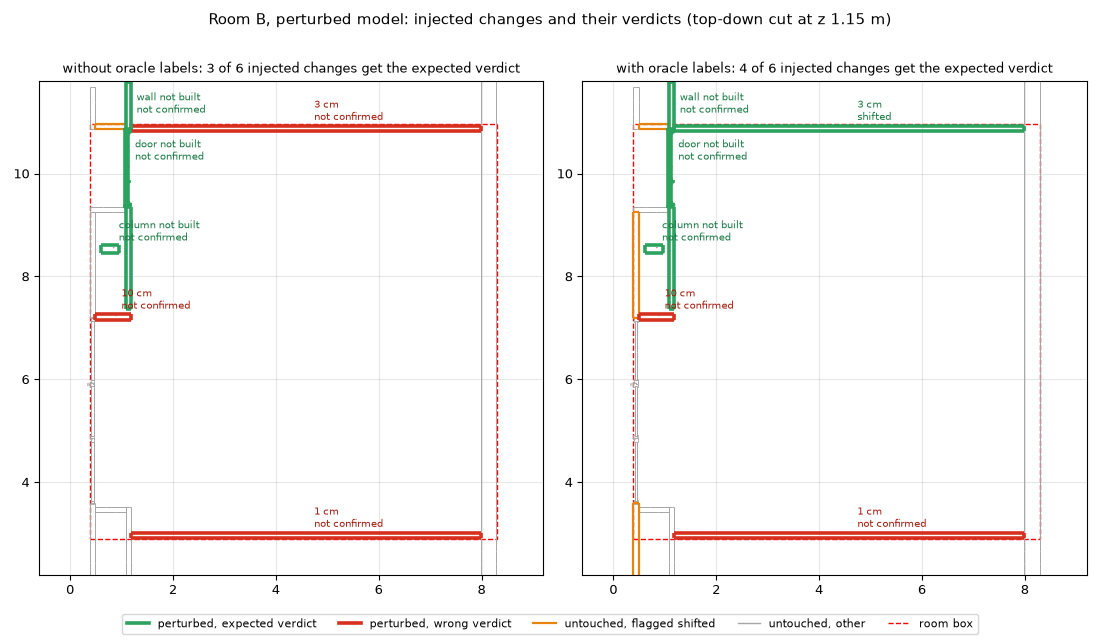

wrote craslabbim_perturbed.ifc manifest.json scores_no_labels.csv scores_oracle_labels.csv scores_top_down.png
peak RSS 1.43 GB, notebook run 430 s


In [14]:
FIELDS = ["global_id", "ifc_class", "name", "change", "injected_offset_mm", "expected", "actual", "baseline", "point_count", "baseline_point_count",
          "median_signed_offset_mm", "baseline_median_mm", "median_change_mm", "share_within_tol", "baseline_share_within_tol", "reason", "correct"]
for variant, rows in SCORES.items():
    with open(OUT / f"scores_{variant}.csv", "w", newline="") as f:
        w = csv.DictWriter(f, FIELDS)
        w.writeheader()
        for r in rows:
            w.writerow({k: ("" if isinstance(v, float) and np.isnan(v) else round(v, 2) if isinstance(v, float) else v) for k, v in {k: r[k] for k in FIELDS}.items()})


def section(els, axis, value):
    # Line segments where the plane axis == value cuts the elements' triangles: (n, 2, 2), two end points in the other two axes.
    keep_axes = [i for i in range(3) if i != axis]
    out = []
    for e in els:
        v = e.vertices
        if v[:, axis].min() >= value or v[:, axis].max() <= value:
            continue
        tri = v[e.faces]
        s = tri[:, :, axis] - value
        S = np.full((len(tri), 2, 2), np.nan)
        count = np.zeros(len(tri), int)
        for i, j in ((0, 1), (1, 2), (2, 0)):
            idx = np.where(s[:, i] * s[:, j] < 0)[0]
            t = s[idx, i] / (s[idx, i] - s[idx, j])
            S[idx, count[idx]] = tri[idx, i][:, keep_axes] + t[:, None] * (tri[idx, j][:, keep_axes] - tri[idx, i][:, keep_axes])
            count[idx] += 1
        out.append(S[count == 2])
    return np.concatenate(out) if out else np.zeros((0, 2, 2))


Z_CUT = 1.15
LABEL = {"moved": lambda c: f"{np.linalg.norm(c['offset_m']) * 100:.0f} cm", "not_built": lambda c: {"IfcDoor": "door", "IfcColumn": "column"}.get(c["ifc_class"], "wall") + " not built"}
fig, axs = plt.subplots(1, 2, figsize=(11, 6.4))
for ax, (variant, title) in zip(axs, (("no_labels", "without oracle labels"), ("oracle_labels", "with oracle labels"))):
    rows = {r["global_id"]: r for r in SCORES[variant]}
    ax.add_collection(LineCollection(section(elements_p, 2, Z_CUT), colors="0.65", linewidths=0.7))
    flagged = [e for e in elements_p if e.global_id not in CHANGE and rows[e.global_id]["actual"] == "shifted"]
    if flagged:
        ax.add_collection(LineCollection(section(flagged, 2, Z_CUT), colors="#e6850e", linewidths=1.6))
    for g, c in CHANGE.items():
        e = by_id_p[g]
        ok = rows[g]["correct"]
        cut = section([e], 2, Z_CUT)
        if len(cut):
            ax.add_collection(LineCollection(cut, colors="#2ca25f" if ok else "#d7301f", linewidths=2.6))
        x, y = (e.vertices[:, :2].min(0) + e.vertices[:, :2].max(0)) / 2
        ax.annotate(f"{LABEL[c['change']](c)}\n{rows[g]['actual']}", (x, y), xytext=(6, 6), textcoords="offset points", fontsize=7,
                    color="#1b7a45" if ok else "#a31d10", arrowprops=dict(arrowstyle="-", lw=0.5, color="0.4"))
    ax.add_patch(plt.Rectangle(box_lo[:2], *(box_hi - box_lo)[:2], fill=False, ec="r", ls="--", lw=1))
    ax.set_xlim(-0.6, 9.2); ax.set_ylim(2.2, 11.8); ax.set_aspect("equal"); ax.grid(alpha=0.3)
    n_ok = sum(bool(rows[g]["correct"]) for g in CHANGE)
    ax.set_title(f"{title}: {n_ok} of {len(CHANGE)} injected changes get the expected verdict", fontsize=9)
fig.legend(handles=[plt.Line2D([], [], color="#2ca25f", lw=2.6, label="perturbed, expected verdict"), plt.Line2D([], [], color="#d7301f", lw=2.6, label="perturbed, wrong verdict"),
                    plt.Line2D([], [], color="#e6850e", lw=1.6, label="untouched, flagged shifted"), plt.Line2D([], [], color="0.65", lw=1, label="untouched, other"),
                    plt.Line2D([], [], color="r", ls="--", lw=1, label="room box")], loc="lower center", ncol=5, fontsize=8)
fig.suptitle("Room B, perturbed model: injected changes and their verdicts (top-down cut at z 1.15 m)")
plt.tight_layout(rect=(0, 0.05, 1, 0.97))
fig.savefig(OUT / "scores_top_down.png", dpi=100)  # 1100 x 640 px
plt.close(fig)
display(Image(filename=str(OUT / "scores_top_down.png"), width=1100))
print("wrote", *sorted(p.name for p in OUT.iterdir()))
print(f"peak RSS {peak_rss_gb():.2f} GB, notebook run {time.time() - T0:.0f} s")

## Answer

Room B of the CRAS lab, 35 elements, 03a's verdict logic and parameters unchanged **including the wall side test of issue #17**, a perturbed model with six recorded changes (`outputs/03b/manifest.json`). **Without oracle labels 3 of 6 injected changes get the verdict they should, with labels 4 of 6** (before the side test: 3 and 2). **Of the three moves only one is right, and only with labels: the 3 cm move.** The 1 cm move is not OK and the 10 cm move is still not shifted. The false-flag rate on untouched elements is low (3.4 % without labels, 6.9 % with). Issue #18's problems (below) are not fixed here and still shape the numbers.

**The perturbed model (unchanged by the side test: the three walls are chosen and the masks made on the baseline's points before the side test leaves out the back of a wall, so the same walls are moved by the same amounts as before).** Moved (towards the room box centre; the three walls inside the box with the most oracle-label points): `Drywall:9615` by **1 cm** (265,408 points), `Drywall:9732` by **3 cm** (257,873) and `Drywall:9786` by **10 cm** (6,037). Not built (scan points of element classes assigned to them in the baseline, left out): the door `0WU0DUvgT6tu4IXFc9kNX5` (**60,398** points), the column `054HMVvnL1EOSZl$bniLeG` (**0**: 03a already found no element-class points on it, so masking it tests nothing) and the wall `Drywall:9790` (**50,550** points), which has the highest share of clutter-class points among the points assigned to it without labels (9.4 %, 5,625 of 59,804). That wall is hardly hidden: only 9.4 % of the points assigned to it are clutter-class, and it was already shifted in the baseline. The selection rule was also widened after a first try: restricted to walls inside the box, every wall had 0 % clutter-class points, so the rule now takes all room walls. The IFC check passed: the 257 `IfcElement` GlobalIds are identical, the three moved walls equal the original plus the offset and the other 32 room elements are unchanged (max error 0 m, tolerance 1e-6), and the check was made against `manifest.json` re-read from disk: of the 261 placed products exactly those the manifest lists changed (the three walls and their 10 `carried` opening elements), each by its recorded offset, and the 10 `held_in_place` windows did not move. Two of the moved walls host 5 windows each, whose placements were compensated; the third hosts none.

**Frame.** Refined against the perturbed model (masked points left out of the ICP as the scan lacks them): correction 0.102 degrees and 9.7 mm against the recorded transform (the real-model refinement: 0.112 degrees, 6.8 mm). The two refinements differ by **0.013 degrees and 13.2 mm, all of it along +y** (0.2, 13.2, 0.0 mm). That is not tiny against a 15 mm tolerance, and the robust loss did not prevent it: the moves alone give 13.2 mm, the masks alone 0.4 mm. I did not investigate why (the plain 10 cm pass runs before the Tukey pass and sees all three walls). It is part of why the moved walls read as they do below.

**Baseline.** On the real model this copy of the logic gives 5 / 0 / 30 without labels and 6 / 1 / 28 with (asserted equal to 03a's, which changed with the side test: it was 5 / 1 / 29 and 6 / 2 / 27).

**Per change** (expected -> actual; share within 15 mm and median in brackets; every actual is the perturbed run's verdict):

| change | expected | without labels | with labels | baseline (no labels / labels) |
|---|---|---|---|---|
| `Drywall:9615` moved 1 cm | OK | not confirmed (67 %, +1.2 mm) | not confirmed (89 %, +1.4 mm) | not confirmed (67 %, -2.0 mm / 90 %, -1.9 mm) |
| `Drywall:9732` moved 3 cm | shifted | not confirmed (7 %, -46.8 mm) | **shifted** (2 %, -47.3 mm) | not confirmed (77 %, -3.8 mm / 92 %, -4.1 mm) |
| `Drywall:9786` moved 10 cm | shifted | not confirmed (1 %, +84.7 mm) | not confirmed (0 %, +54.9 mm) | not confirmed (+54.2 mm / +54.7 mm) |
| door not built | not confirmed | not confirmed (7,337 points left) | not confirmed (1,617, too few) | not confirmed |
| column not built | not confirmed | not confirmed (82, too few) | not confirmed (2, too few) | not confirmed |
| `Drywall:9790` not built | not confirmed | not confirmed (11,628 points left, +69.6 mm) | not confirmed (3,235 left, +55.6 mm) | not confirmed |

**Why each move reads as it does.**
- *1 cm, `Drywall:9615`* (a control: it should stay OK). It was **not OK in the baseline** (90 % with labels, 67 % without), so it cannot be OK after a 1 cm move. The side test did what it should for it (45 % of its band points are the back of the wall and are left out, 13 % ambiguous; the offsets are one cluster at about 0, p10 to p90 -6 to +2 mm), but 10 % of its labelled points are outside 15 mm for reasons that no side test removes (for `Drywall:9732`, the same kind of wall, 03a finds they are mostly at junctions and window reveals; I did not check this for `Drywall:9615`). The median changes by +3.3 mm with labels where the injected change is -10 mm: that is -10 mm plus the frame, see next.
- *3 cm, `Drywall:9732`.* Right with labels: the median goes from -4.1 to -47.3 mm, one cluster (p10 to p90 -51 to -45 mm), 2 % within 15 mm, so shifted. Without labels clutter and unassigned points keep the cluster share under 80 %, so not confirmed. The median moved by **-43.2 mm, where the injected change is -30 mm**: the other 13.2 mm are the frame (next paragraph). This is the first moved wall in 03a / 03b that is read as moved: before the side test it was not one cluster at all (a third of its points were on the neighbour's surface).
- *10 cm, `Drywall:9786`*, a two-sided partition. **Not read as moved.** 97 % of its points are ambiguous in the baseline (79 % in the perturbed run): occupied on both sides within 20 cm, so the side test cannot tell which face a point is, the nearest face decides, and a scan surface 10 cm from the model face is on the old far face: the median hardly changes (54.7 -> 54.9 mm with labels), the share within 15 mm is 0 % in both. The side test fixes this case only where the scan shows which side a surface was seen from, and it does not here. A 10 cm move of a 10 cm partition is also a degenerate test for any rule that measures to the nearest face.
- *Not built.* All three are not confirmed, which is the expected verdict. The **wall** is now right with labels (the earlier version scored it wrong because `Drywall:9790` was shifted in the baseline; it is not confirmed now, see 03a), but the reason is not good: 3,235 element-class points still land on it (masking works on the baseline's assignment; the perturbed run assigns again), the same leak as before (issue #18). The **door** has 1,617 points left (too few with labels, 7,337 without, 51 % within 15 mm: not confirmed by inconsistent offsets, i.e. clutter and neighbours, not by the missing door). The **column** has 0 points in the baseline, so masking it tests nothing (#18).

**The frame is the main remaining cause of the 1 and 3 cm readings (issue #18).** The ICP refinement against the perturbed model differs from the real one by 13.2 mm along +y (rotation 0.013 degrees): 13.2 mm from the moves alone, 0.4 mm from the masks alone. A wall with its room on the +y side reads +13.2 mm of it, one with its room on -y reads -13.2 mm: `Drywall:9615` (+y): -10 + 13.2 = +3.2 mm, measured +3.3; `Drywall:9732` (-y): -30 - 13.2 = -43.2 mm, measured -43.2. So the readings match "injected change plus the frame" to 0.1 mm, and a 1 cm move is indistinguishable from the frame error. The 3 cm move is read as 47 mm, 17 mm too much, and is shifted anyway.

**Collateral.** All five windows that were OK in the baseline are hosted by the two moved walls with windows, and all five became not confirmed (medians within 3 mm, shares under 95 %); I did not check whether it is the frame shift or the moved wall's face taking their edge points. The other 23 untouched elements keep their baseline verdict except `Drywall:9768`.

**False shifted/missing rate on the 29 untouched elements (the gate number, the absolute count).** Missing never occurs (no scanner positions). Untouched elements whose perturbed-run verdict is shifted: without labels **1 of 29 (3.4 %)**, with labels **2 of 29 (6.9 %)**. As context, those not already shifted in the baseline (new): 1 of 29 (3.4 %) in both variants, `Drywall:9768` (`976859`, not confirmed -> shifted at +94 mm; its points are door-class and the door's points are masked in this run; I did not trace it further). The extra one with labels is the west wall `Drywall:9625` (`962532`), shifted at -134 mm in the baseline already: a finding on the real scan, which this notebook cannot separate from the perturbation. Both variants are under the gate's 10 %.

**What it says about the 05 gate** ("every injected change beyond tolerance gets the right verdict, and at most 10 % of untouched elements are falsely flagged shifted or missing"): the second clause passes (3.4 % without labels, 6.9 % with). The first still fails: of the two moves beyond tolerance, **0 of 2 are right without labels and 1 of 2 with labels** (the 3 cm move; the 10 cm partition is not), and the 1 cm control is not OK. What would change that is not in 03a's wall model any more: a frame that the moves do not drag by 13 mm (#18), a move of a wall that the baseline reads as one clean plane within tolerance (03a found `Drywall:9732` is the only such wall and its OK share is 91.7 %, below 95 %, for junction points; a margin around other elements would make it OK) and a partition whose side the scan can show.
